# **INFORMASI DATASET**

Dataset ini menyajikan gambaran mendalam mengenai perilaku transaksi dan pola aktivitas keuangan, sehingga sangat ideal untuk eksplorasi **deteksi penipuan (fraud detection)** dan **identifikasi anomali**. Dataset ini mencakup **2.512 sampel data transaksi**, yang mencakup berbagai atribut transaksi, demografi nasabah, dan pola penggunaan.

Setiap entri memberikan wawasan komprehensif terhadap perilaku transaksi, memungkinkan analisis untuk **keamanan finansial** dan pengembangan model prediktif.

## Fitur Utama

- **`TransactionID`**: Pengidentifikasi unik alfanumerik untuk setiap transaksi.  
- **`AccountID`**: ID unik untuk setiap akun, dapat memiliki banyak transaksi.  
- **`TransactionAmount`**: Nilai transaksi dalam mata uang, mulai dari pengeluaran kecil hingga pembelian besar.  
- **`TransactionDate`**: Tanggal dan waktu transaksi terjadi.  
- **`TransactionType`**: Tipe transaksi berupa `'Credit'` atau `'Debit'`.  
- **`Location`**: Lokasi geografis transaksi (nama kota di Amerika Serikat).  
- **`DeviceID`**: ID perangkat yang digunakan dalam transaksi.  
- **`IP Address`**: Alamat IPv4 yang digunakan saat transaksi, dapat berubah untuk beberapa akun.  
- **`MerchantID`**: ID unik merchant, menunjukkan merchant utama dan anomali transaksi.  
- **`AccountBalance`**: Saldo akun setelah transaksi berlangsung.  
- **`PreviousTransactionDate`**: Tanggal transaksi terakhir pada akun, berguna untuk menghitung frekuensi transaksi.  
- **`Channel`**: Kanal transaksi seperti `Online`, `ATM`, atau `Branch`.  
- **`CustomerAge`**: Usia pemilik akun.  
- **`CustomerOccupation`**: Profesi pengguna seperti `Dokter`, `Insinyur`, `Mahasiswa`, atau `Pensiunan`.  
- **`TransactionDuration`**: Lama waktu transaksi (dalam detik).  
- **`LoginAttempts`**: Jumlah upaya login sebelum transaksi—jumlah tinggi bisa mengindikasikan anomali.

Tugas kamu adalah membuat model clustering yang selanjutnya akan digunakan untuk membuat model klasifikasi.


# **Penting**
- Jangan mengubah atau menambahkan cell text yang sudah disediakan, Anda hanya perlu mengerjakan cell code yang sudah disediakan.
- Pastikan seluruh kriteria memiliki output yang sesuai, karena jika tidak ada output dianggap tidak selesai.
- Misal, Anda menggunakan df = df.dropna() silakan gunakan df.isnull().sum() sebagai tanda sudah berhasil. Silakan sesuaikan seluruh output dengan perintah yang sudah disediakan.
- Pastikan Anda melakukan Run All sebelum mengirimkan submission untuk memastikan seluruh cell berjalan dengan baik.
- Pastikan Anda menggunakan variabel df dari awal sampai akhir dan tidak diperbolehkan mengganti nama variabel tersebut.
- Hapus simbol pagar (#) pada kode yang bertipe komentar jika Anda menerapkan kriteria tambahan
- Biarkan simbol pagar (#) jika Anda tidak menerapkan kriteria tambahan
- Pastikan Anda mengerjakan sesuai section yang sudah diberikan tanpa mengubah judul atau header yang disediakan.

# **1. Import Library**
Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning. Semua library yang dibutuhkan harus **import** di **cell** ini, jika ada library yang dijalankan di cell lain maka **submission langsung ditolak**

In [113]:
import pandas as pd
import seaborn as sns
import matplotlib
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer
import joblib
from sklearn.impute import SimpleImputer
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

# **2. Memuat Dataset**
Pada tahap ini, Anda perlu memuat dataset ke dalam notebook lalu mengecek informasi dataset sebelum nantinya dilakukan pembersihan. Hal-hal yang perlu dilakukan pada tahapan ini yaitu:
1. **Memahami Struktur Data**
   - Dataset harus mengambil referensi wajib digunakan (bisa dilihat [Disini](https://drive.google.com/drive/folders/1Zs7VmPZ-jNwsRlMKH65Ea-LApSwx6lKx?usp=drive_link))
   - Melakukan loading dataset ke dalam notebook dan menampilkan 5 baris pertama dengan function `head`.
   - Tinjau jumlah baris kolom dan jenis data dalam dataset dengan function `info`.  
   - Menampilkan statistik deskriptif dataset dengan menjalankan `describe`.
   - Pastikan **setiap function tersebut** memiliki **output pada setiap cell** code. Jika tidak **submission langsung ditolak**
   

Gunakan code ini untuk melakukan load data secara otomatis tanpa harus download data tersebut secara manual:
```python
url='https://drive.google.com/uc?id=1gnLO9qvEPqv1uBt1928AcsCmdvzqjC5m'
df = pd.read_csv(url)
```

Penting: pada kriteria pertama hindari penggunaan print() dan display() karena seluruh fungsi yang digunakan sudah memiliki standar output dan menghasilkan output yang diharapkan.

Kriteria 1 akan ditolak ketika:
- print(__.head())
- display(___.head())
dst

Kriteria 1 akan diterima ketika Anda menggunakan fungsi yang diminta tanpa menambahkan deskripsi apapun.

In [114]:
url='https://drive.google.com/uc?id=1gnLO9qvEPqv1uBt1928AcsCmdvzqjC5m'
df = pd.read_csv(url)

In [115]:
df.head()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,198.0,1.0,7429.40,2024-11-04 08:06:39


In [116]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2508 non-null   object 
 1   AccountID                2516 non-null   object 
 2   TransactionAmount        2511 non-null   float64
 3   TransactionDate          2509 non-null   object 
 4   TransactionType          2507 non-null   object 
 5   Location                 2507 non-null   object 
 6   DeviceID                 2507 non-null   object 
 7   IP Address               2517 non-null   object 
 8   MerchantID               2514 non-null   object 
 9   Channel                  2510 non-null   object 
 10  CustomerAge              2519 non-null   float64
 11  CustomerOccupation       2514 non-null   object 
 12  TransactionDuration      2511 non-null   float64
 13  LoginAttempts            2516 non-null   float64
 14  AccountBalance          

In [117]:
df.describe()

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2511.000000,2519.000000,2511.000000,2516.000000,2510.000000
mean,297.656468,44.678444,119.422939,1.121622,5113.438124
std,292.230367,17.837359,70.078513,0.594469,3897.975861
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.310000,27.000000,63.000000,1.000000,1504.727500
50%,211.360000,45.000000,112.000000,1.000000,4734.110000
75%,413.105000,59.000000,161.000000,1.000000,7672.687500
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


(Opsional) Memuat Dataset dan Melakukan Exploratory Data Analysis (EDA) [Skilled]

**Biarkan kosong jika tidak menerapkan kriteria skilled**

**Apabila ingin menerapkan Advanced, pastikan seluruh visualisasi tidak ada yang overlap**

In [118]:
# Menampilkan korelasi antar fitur (Opsional Skilled 1)

In [119]:
# Menampilkan histogram untuk semua kolom numerik (Opsional Skilled 1)

(Opsional) Memuat Dataset dan Melakukan Exploratory Data Analysis (EDA) [Advanced]

**Biarkan kosong jika tidak menerapkan kriteria advanced**

In [120]:
# Visualisasi yang lebih informatif (Opsional Advanced 1)

# **3. Pembersihan dan Pra Pemrosesan Data**

Pada tahap ini, Anda akan melakukan **Pembersihan Dataset** untuk menjadikan dataset mudah diintepretasi dan bisa dilatih. Hal-hal yang wajib kamu lakukan yaitu:

1. **Mengecek dataset** menggunakan isnull().sum() dan duplicated().sum().
2. Melakukan feature scaling menggunakan `MinMaxScaler()` atau `StandardScalar()` untuk fitur numerik.
3. Melakukan feature encoding menggunakan `LabelEncoder()` untuk fitur kategorikal.
4. Melakukan drop pada kolom id.
5. **Ketentuan Cell Code**
   - Pastikan **setiap pemeriksaan tersebut** memiliki **output pada cell-nya**. Jika tidak **submission langsung ditolak**


In [121]:
df.isnull().sum()

,0
TransactionID,29
AccountID,21
TransactionAmount,26
TransactionDate,28
TransactionType,30
Location,30
DeviceID,30
IP Address,20
MerchantID,23
Channel,27


In [122]:
df.duplicated().sum()

np.int64(21)

In [123]:
numerical_cols = ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']

for col in numerical_cols:
    median_value = df[col].median()
    df[col].fillna(median_value, inplace=True)

scaler = MinMaxScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

df.head()

/tmp/ipython-input-3358620047.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(median_value, inplace=True)


,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,0.007207,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,0.838710,Doctor,0.244828,0.0,0.336832,2024-11-04 08:08:08
1,TX000002,AC00455,0.195940,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,0.806452,Doctor,0.451724,0.0,0.918055,2024-11-04 08:09:35
2,TX000003,AC00019,0.065680,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,0.016129,Student,0.158621,0.0,0.068637,2024-11-04 08:07:04
3,TX000004,AC00070,0.096016,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,0.129032,Student,0.051724,0.0,0.569198,2024-11-04 08:09:06
4,TX000005,AC00411,0.006874,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,0.435484,Student,0.648276,0.0,0.492591,2024-11-04 08:06:39


In [124]:

columns_to_drop = ['TransactionID', 'AccountID', 'DeviceID', 'IP Address', 'MerchantID']
df.drop(columns=columns_to_drop, inplace=True)

In [125]:



categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    mode_value = df[col].mode()[0]
    df[col].fillna(mode_value, inplace=True)

label_encoder = LabelEncoder()
for col in categorical_cols:
    df[col] = label_encoder.fit_transform(df[col])

df.head()

/tmp/ipython-input-2160011160.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(mode_value, inplace=True)


,TransactionAmount,TransactionDate,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,0.007207,680,1,36,0,0.838710,0,0.244828,0.0,0.336832,105
1,0.195940,1178,1,15,0,0.806452,0,0.451724,0.0,0.918055,192
2,0.065680,1262,1,23,2,0.016129,3,0.158621,0.0,0.068637,41
3,0.096016,818,1,33,2,0.129032,3,0.051724,0.0,0.569198,163
4,0.006874,1939,0,1,2,0.435484,3,0.648276,0.0,0.492591,16


In [126]:


df.columns.tolist()

['TransactionAmount',
 'TransactionDate',
 'TransactionType',
 'Location',
 'Channel',
 'CustomerAge',
 'CustomerOccupation',
 'TransactionDuration',
 'LoginAttempts',
 'AccountBalance',
 'PreviousTransactionDate']

(Opsional) Pembersihan dan Pra Pemrosesan Data [Skilled]

**Biarkan kosong jika tidak menerapkan kriteria skilled**

In [127]:

print(f"Jumlah baris sebelum dropna: {len(df)}")
df.dropna(inplace=True)
print(f"Jumlah baris setelah dropna: {len(df)}")
print("\nJumlah nilai null setelah dropna:")
df.isnull().sum()

Jumlah baris sebelum dropna: 2537
Jumlah baris setelah dropna: 2537

Jumlah nilai null setelah dropna:


,0
TransactionAmount,0
TransactionDate,0
TransactionType,0
Location,0
Channel,0
CustomerAge,0
CustomerOccupation,0
TransactionDuration,0
LoginAttempts,0
AccountBalance,0


In [128]:

print(f"Jumlah baris sebelum dropna: {len(df)}")
df.dropna(inplace=True)
print(f"Jumlah baris setelah dropna: {len(df)}")
print("\nJumlah nilai null setelah dropna:")
df.isnull().sum()

Jumlah baris sebelum dropna: 2537
Jumlah baris setelah dropna: 2537

Jumlah nilai null setelah dropna:


,0
TransactionAmount,0
TransactionDate,0
TransactionType,0
Location,0
Channel,0
CustomerAge,0
CustomerOccupation,0
TransactionDuration,0
LoginAttempts,0
AccountBalance,0


(Opsional) Pembersihan dan Pra Pemrosesan Data [Advanced]

**Biarkan kosong jika tidak menerapkan kriteria advanced**

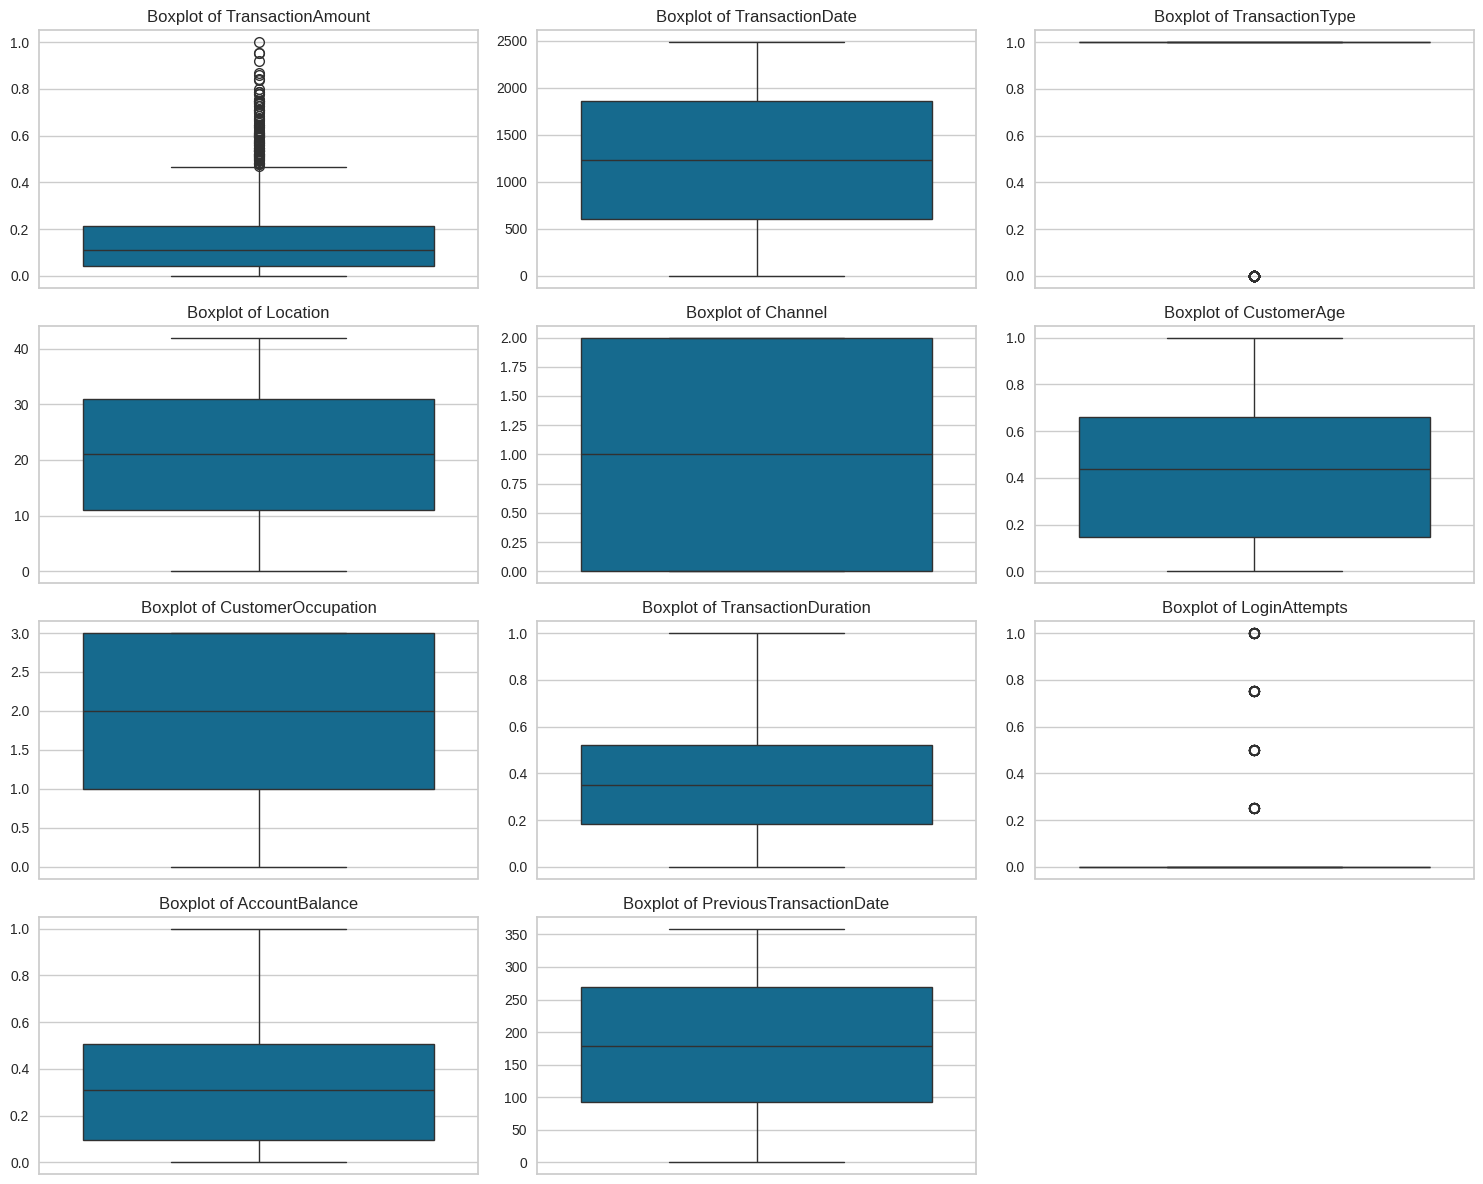

In [129]:
import matplotlib.pyplot as plt
import seaborn as sns


numerical_cols = df.select_dtypes(include=['number']).columns
plt.figure(figsize=(15, 12))
for i, col in enumerate(numerical_cols):

    plt.subplot(4, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')
    plt.ylabel('')
plt.tight_layout()
plt.show()

In [130]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder


age_bins = [17, 30, 55, 81]
age_labels = ['Remaja', 'Dewasa', 'Senior']
df['AgeGroup'] = pd.cut(df['CustomerAge'], bins=age_bins, labels=age_labels, right=False)
amount_bins = [0, 100, 500, 2000]
amount_labels = ['Kecil', 'Sedang', 'Besar']
df['TransactionCategory'] = pd.cut(df['TransactionAmount'], bins=amount_bins, labels=amount_labels, right=False)
label_encoder = LabelEncoder()
df['AgeGroup'] = label_encoder.fit_transform(df['AgeGroup'])
df['TransactionCategory'] = label_encoder.fit_transform(df['TransactionCategory'])


print("Hasil Binning dan Encoding:")
print(df[['CustomerAge', 'AgeGroup', 'TransactionAmount', 'TransactionCategory']].head(10))

print("\nDistribusi Kategori Usia (0: Dewasa, 1: Remaja, 2: Senior):")
print(df['AgeGroup'].value_counts())

print("\nDistribusi Kategori Transaksi (0: Besar, 1: Kecil, 2: Sedang):")
print(df['TransactionCategory'].value_counts())

Hasil Binning dan Encoding:
   CustomerAge  AgeGroup  TransactionAmount  TransactionCategory
0     0.838710         0           0.007207                    0
1     0.806452         0           0.195940                    0
2     0.016129         0           0.065680                    0
3     0.129032         0           0.096016                    0
4     0.435484         0           0.006874                    0
5     0.000000         0           0.047888                    0
6     0.306452         0           0.003554                    0
7     0.790323         0           0.089199                    0
8     0.532258         0           0.055226                    0
9     0.596774         0           0.425098                    0

Distribusi Kategori Usia (0: Dewasa, 1: Remaja, 2: Senior):
AgeGroup
0    2537
Name: count, dtype: int64

Distribusi Kategori Transaksi (0: Besar, 1: Kecil, 2: Sedang):
TransactionCategory
0    2537
Name: count, dtype: int64


# **4. Membangun Model Clustering**
Pada tahap ini, Anda membangun model clustering dengan memilih algoritma yang sesuai untuk mengelompokkan data berdasarkan kesamaan.
1. Pastikan Anda menggunakan dataframe yang sudah melalui processing sesuai dengan levelnya (Basic, Skilled, Advanced)
2. Melakukan visualisasi Elbow Method untuk menentukan jumlah cluster terbaik menggunakan `KElbowVisualizer()`.
3. Menggunakan algoritma K-Means Clustering dengan `sklearn.cluster.KMeans()`.
4. Jalankan cell code `joblib.dump(model_kmeans, "model_clustering.h5")` untuk menyimpan model yang sudah dibuat.

In [131]:

df.describe()

,TransactionAmount,TransactionDate,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate,AgeGroup,TransactionCategory
count,2537.000000,2537.000000,2537.000000,2537.000000,2537.000000,2537.000000,2537.000000,2537.000000,2537.000000,2537.000000,2537.000000,2537.0,2537.0
mean,0.154526,1228.349626,0.777296,20.964525,0.988175,0.430334,1.521876,0.377058,0.030154,0.336643,179.231770,0.0,0.0
std,0.151580,725.438951,0.416143,12.196453,0.804572,0.286677,1.133626,0.240422,0.148026,0.260633,102.485276,0.0,0.0
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0
25%,0.043156,601.000000,1.000000,11.000000,0.000000,0.145161,1.000000,0.182759,0.000000,0.095323,92.000000,0.0,0.0
50%,0.110014,1227.000000,1.000000,21.000000,1.000000,0.435484,2.000000,0.351724,0.000000,0.311416,178.000000,0.0,0.0
75%,0.213331,1857.000000,1.000000,31.000000,2.000000,0.661290,3.000000,0.520690,0.000000,0.505876,269.000000,0.0,0.0
max,1.000000,2484.000000,1.000000,42.000000,2.000000,1.000000,3.000000,1.000000,1.000000,1.000000,359.000000,0.0,0.0


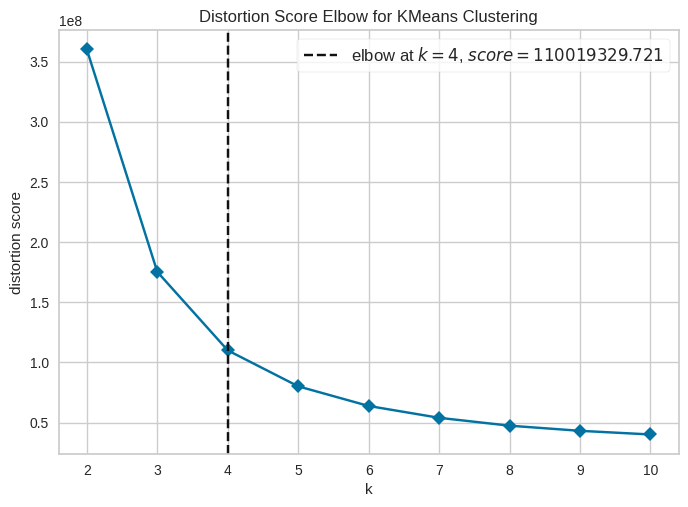

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [132]:



model = KMeans(random_state=42, n_init=10)


visualizer = KElbowVisualizer(
    model, k=(2,11), metric='distortion', timings=False
)


visualizer.fit(df)


visualizer.show()

In [133]:



df_num = df.select_dtypes(include=['int64','float64'])
imputer = SimpleImputer(strategy='mean')
df_num_imputed = pd.DataFrame(imputer.fit_transform(df_num), columns=df_num.columns)

print("Jumlah NaN sebelum imputasi:")
print(df_num.isnull().sum())

print("\nJumlah NaN sesudah imputasi:")
print(df_num_imputed.isnull().sum())


optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans.fit(df_num_imputed)
df['cluster'] = kmeans.labels_

print("\nDataFrame dengan Hasil Clustering:")
print(df.head())




Jumlah NaN sebelum imputasi:
TransactionAmount          0
TransactionDate            0
TransactionType            0
Location                   0
Channel                    0
CustomerAge                0
CustomerOccupation         0
TransactionDuration        0
LoginAttempts              0
AccountBalance             0
PreviousTransactionDate    0
AgeGroup                   0
TransactionCategory        0
dtype: int64

Jumlah NaN sesudah imputasi:
TransactionAmount          0
TransactionDate            0
TransactionType            0
Location                   0
Channel                    0
CustomerAge                0
CustomerOccupation         0
TransactionDuration        0
LoginAttempts              0
AccountBalance             0
PreviousTransactionDate    0
AgeGroup                   0
TransactionCategory        0
dtype: int64

DataFrame dengan Hasil Clustering:
   TransactionAmount  TransactionDate  TransactionType  Location  Channel  \
0           0.007207              680           

Jalankan cell code ini untuk menyimpan model kamu.

In [134]:
joblib.dump(kmeans, "model_clustering.h5")

print("Model clustering berhasil disimpan sebagai 'model_clustering.h5'")



Model clustering berhasil disimpan sebagai 'model_clustering.h5'


(Opsional) Membangun Model Clustering [Skilled]

**Biarkan kosong jika tidak menerapkan kriteria skilled**

In [135]:
# Membuat visualisasi hasil clustering

(Opsional) Membangun Model Clustering [Advanced]

**Biarkan kosong jika tidak menerapkan kriteria advanced**

In [136]:
# Membangun model menggunakan PCA.
# ___ =PCA(n_components=<x>)
# ___ = ____.fit_transform(___)
# Menyimpan data PCA sebagai Dataframe dengan nama PCA_<numbers>
# <data_final> = pd.DataFrame(___, columns=['PCA1', 'PCA2', <sesuaikan dengan jumlah n>])
# Pastikan kamu membangun model Kmeans baru dengan data yang sudah dimodifikasi melalui PCA.
# ___ = KMeans(n_clusters=<x>)
# ___.fit(<data_final>)

In [137]:
# Simpan model PCA sebagai perbandingan dengan menjalankan cell code ini joblib.dump(model,"PCA_model_clustering.h5")
# Pastikan yang disimpan model yang sudah melalui .fit berdasarkan dataset yang sudah dilakukan PCA
# joblib.dump(___, "PCA_model_clustering.h5")

# **5. Interpretasi Cluster**

## **a. Interpretasi Hasil Clustering**
1. **Contoh Interpretasi:**
- **Cluster 1: (Nasabah Bertransaksi dan Pendapatan Besar)**:
  - **Rata-rata (mean) Annual Income:** 0.953 (48,260)
  - **Rata-rata (mean) Spending Score:** 0.8 (56.48)
  - **Analisis:** Cluster ini mencakup pelanggan dengan pendapatan tahunan tinggi dan tingkat pengeluaran yang cukup tinggi. Pelanggan dalam cluster ini cenderung memiliki daya beli yang tinggi dan mereka lebih cenderung untuk membelanjakan sebagian besar pendapatan mereka. Sehingga rekomendasi pada kelompok nasabah ini adalah dengan menawarkan produk-produk investasi atau perbankan yang berkualitas tinggi.


In [138]:
# Menampilkan analisis deskriptif minimal mean, min dan max untuk fitur numerik.
# Silakan menambahkan fungsi agregasi lainnya untuk experience lebih baik.
# pastikan output menghasilkan agregasi dan groupby bersamaan dengan mean, min, dan max.
numerical_cols = df.select_dtypes(include=["int64","float64"]).columns
cluster_analysis = df.groupby("cluster").agg(["min", "max", "mean"])
cluster_analysis

TransactionAmount                     TransactionDate        \
                      min       max      mean             min   max   
cluster                                                               
0                0.000031  1.000000  0.156612             816  1651   
1                0.000313  0.953561  0.148874               0   815   
2                0.000000  0.954092  0.158170            1652  2484   

                     TransactionType               Location  ...  \
                mean             min max      mean      min  ...   
cluster                                                      ...   
0        1233.856635               0   1  0.772512        0  ...   
1         394.935522               0   1  0.790152        0  ...   
2        2069.128571               0   1  0.769048        0  ...   

        AccountBalance PreviousTransactionDate                  AgeGroup      \
                  mean                     min  max        mean      min max   
cluster                                                                        
0             0.328583                       0  359  174.426540        0   0   
1             0.333054                       0  358  183.665885        0   0   
2             0.348386                       0  359  179.557143        0   0   

             TransactionCategory           
        mean                 min max mean  
cluster                                    
0        0.0                   0   0  0.0  
1        0.0                   0   0  0.0  
2        0.0                   0   0  0.0  

[3 rows x 39 columns]

## Menjelaskan karakteristik tiap cluster berdasarkan rentangnya.
1. **Cluster 0: (Pelanggan Umum dengan Transaksi Bervariasi):**
    - **Rata-rata (mean) TransactionAmount: 0.156**
    - **Rata-rata (mean) AccountBalance: 0.328**
    - **Analisis:** Cluster ini mencakup pelanggan dengan rentang transaksi yang sangat lebar, mulai dari yang bernilai kecil hingga yang paling besar di antara semua pelanggan. Namun, mereka memiliki rata-rata saldo akun yang paling rendah. Ini menunjukkan bahwa meskipun ada beberapa transaksi bernilai tinggi, secara umum pelanggan di kelompok ini tidak menyimpan banyak dana di akun mereka. Sehingga rekomendasi untuk pelanggan di cluster ini yang melakukan transaksi besar, tawarkan produk tabungan atau investasi dengan imbal hasil menarik untuk mendorong mereka meningkatkan saldo. Untuk mayoritas lainnya, berikan penawaran promosi berbasis volume transaksi untuk meningkatkan engagement.

2. **Cluster 1: (Pelanggan Lama & Tidak Aktif)**
     - **Rata-rata (mean) TransactionAmount: 0.148**
     - **Rata-rata (mean) AccountBalance: 0.333**
     - **Analisis:** Cluster ini berisi pelanggan dengan riwayat transaksi paling lama dan rata-rata nilai transaksi yang paling rendah. Jeda waktu antar transaksi mereka juga yang paling lama, menandakan tingkat aktivitas yang rendah. Pelanggan dalam cluster ini kemungkinan besar sudah tidak aktif lagi atau jarang sekali bertransaksi. Sehingga rekomendasinya yaitu jalankan kampanye re-engagement (aktivasi kembali) yang ditargetkan khusus untuk kelompok ini. Tawarkan promosi "kembali lagi", diskon khusus, atau insentif lain untuk mendorong mereka melakukan transaksi kembali dan mencegah churn.

3. **Cluster 2: (Pelanggan Loyal & Bernilai Tinggi)**
    - **Rata-rata (mean) TransactionAmount: 0.158**
    - **Rata-rata (mean) AccountBalance: 0.348**
    - **Analisis:** Cluster ini adalah segmen pelanggan yang paling ideal. Mereka adalah pelanggan yang aktif baru-baru ini, memiliki rata-rata saldo akun dan rata-rata nilai transaksi yang tertinggi. Pelanggan di cluster ini memiliki daya beli dan loyalitas yang tinggi. Sehingga rekomendasinya yaitu fokus pada retensi pelanggan di kelompok ini. Tawarkan program loyalitas, akses prioritas, atau produk premium. Mereka adalah kandidat utama untuk strategi cross-selling dan up-selling produk keuangan lainnya.

# **6. Mengeksport Data**

1. Simpan nama kolom hasil clustering dengan nama `Target`.
2. Simpan hasilnya ke dalam file CSV menggunakan function `to_csv()`.

In [139]:
df.rename(columns={'cluster': 'Target'}, inplace=True)
print("Nama kolom setelah diubah:", df.columns)

Nama kolom setelah diubah: Index(['TransactionAmount', 'TransactionDate', 'TransactionType', 'Location',
       'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration',
       'LoginAttempts', 'AccountBalance', 'PreviousTransactionDate',
       'AgeGroup', 'TransactionCategory', 'Target'],
      dtype='object')


In [140]:
df.to_csv('data_clustering.csv', index=False)

(Opsional) Interpretasi Hasil Clustering [Skilled]

**Biarkan kosong jika tidak menerapkan kriteria skilled**

In [141]:
# inverse dataset ke rentang normal untuk numerikal
# df[numerical_cols] = <nama_scaler>.inverse_transform(df[numerical_cols])
# tampilkan dataset yang sudah di-inverse
# ___.head()

In [142]:
# inverse dataset yang sudah diencode ke kategori aslinya.
# Lengkapi kode berikut jika ingin menerapkan kriteria ini (silakan hapus simbol pagar pada kode yang akan digunakan.)
# for ___ in categorical_cols:
#     ___ = encoders[col]
#     df[col] = ___.inverse_transform(df_inverse[col].astype(int))
# tampilkan dataset yang sudah di-inverse
# ___.head()

In [143]:
# Lakukan analisis deskriptif minimal mean, min dan max untuk fitur numerik dan mode untuk kategorikal seperti pada basic tetapi menggunakan data yang sudah diinverse.
# pastikan output menghasilkan agregasi dan groupby bersamaan dengan mean, min, dan max kembali setelah melakukan inverse.

## Menjelaskan karakteristik tiap cluster berdasarkan rentangnya setelah inverse.
1. **Cluster 1: (___)**:
  - **Rata-rata (mean) <Fitur>:** <Sebelum inverse> <Setelah inverse>
  - **Analisis:** Cluster ini ...

(Opsional) Interpretasi Hasil Clustering [Advanced]

**Biarkan kosong jika tidak menerapkan kriteria advanced**

In [144]:
# Mengintegrasikan kembali data yang telah di-inverse dengan hasil cluster.

In [145]:
# Simpan Data
# ___.to_csv('data_clustering_inverse.csv', index=False)

End of Code.